In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib
from matplotlib.lines import Line2D
from matplotlib.patches import Ellipse
import matplotlib.patches as mpatches
import h5py
import pickle
from scipy.integrate import simpson

In [3]:
def compact_exp_format(num):
    s = "{:.1e}".format(num)  # one decimal place
    base, exp = s.split("e")
    exp = int(exp)
    # Return a string that is already in math mode
    return r"{} \times 10^{{{}}}".format(base, exp)

In [14]:
from feedback_mimic import (
    Mtot_to_MDelta, get_some_quantities, get_spectra
)

##### Feedback Matching Profile

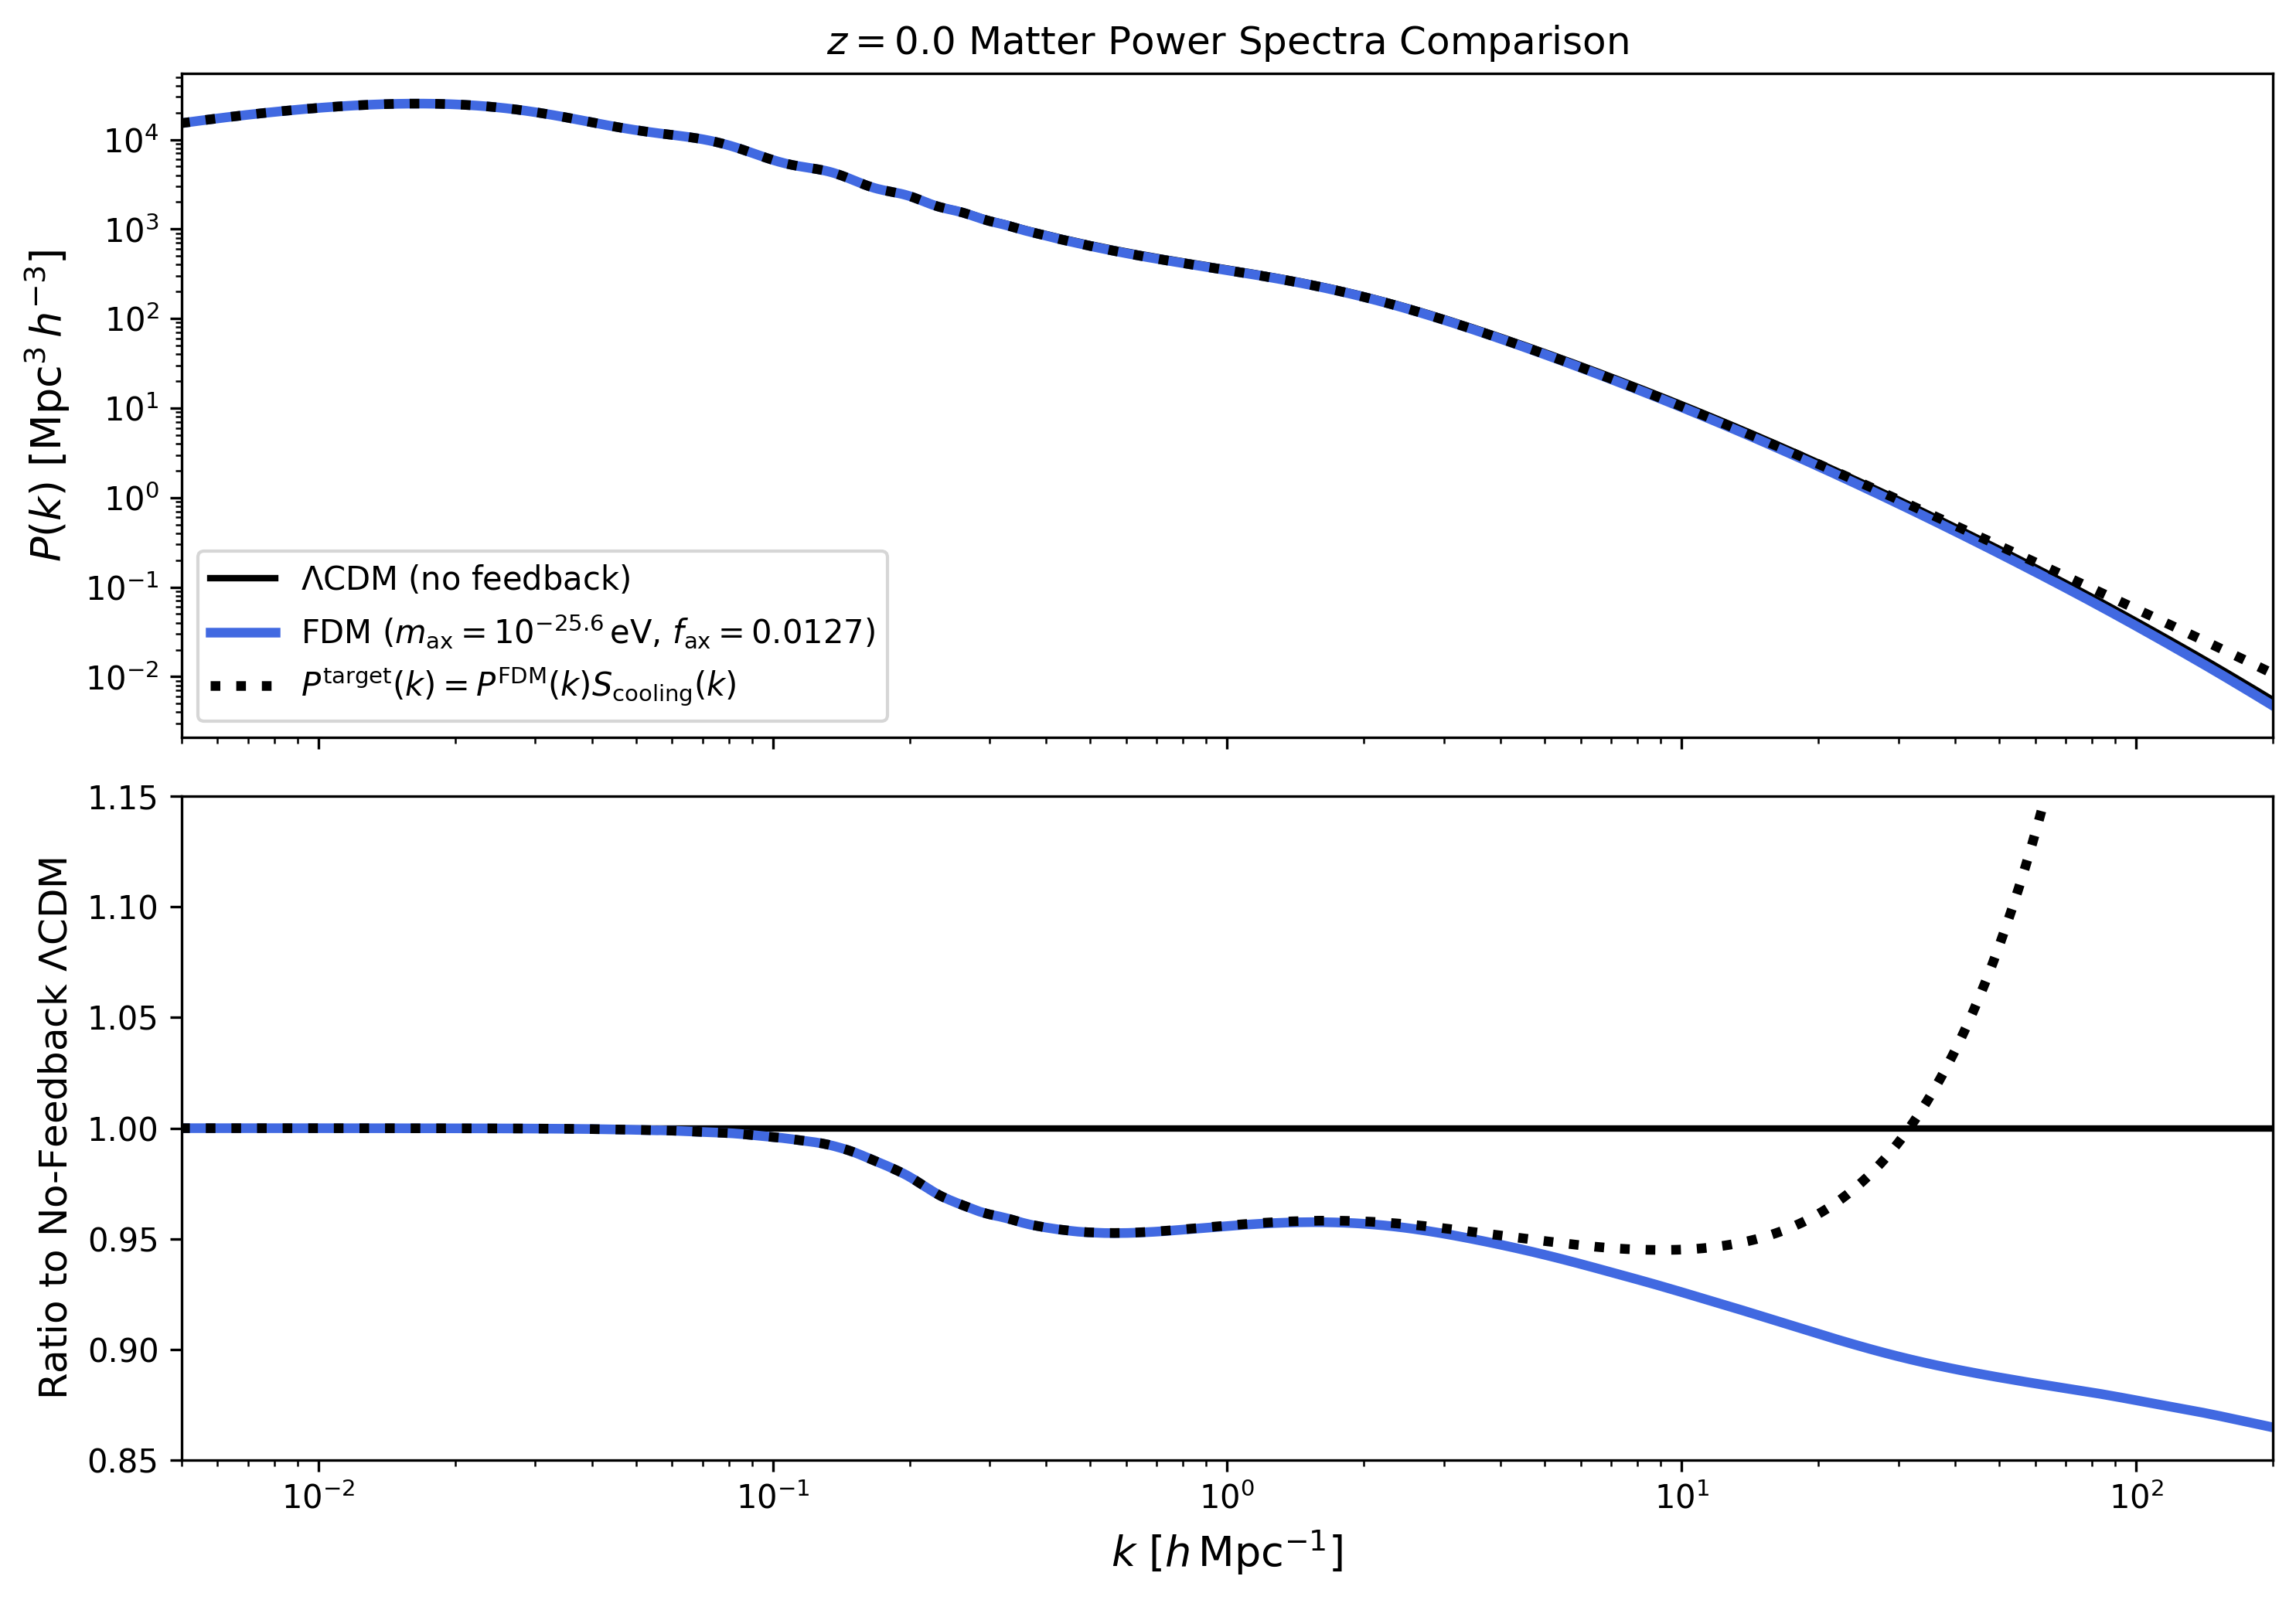

In [34]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 7), dpi=300, sharex=True, height_ratios=[1.0,1.0])

z = 0.0

with open(f"results/halo_model/{z}_data_LCDM_full2h_preferred.pkl", "rb") as f:
    data_LCDM = pickle.load(f)
with open(f"results/halo_model/{z}_data_FDM_full2h_preferred.pkl", "rb") as f:
    data_FDM_preferred = pickle.load(f)

r_v, rho_crit, rho_char, concentration, r_s, Delta_vir, rho_0, rho_0_wh = get_some_quantities(data_LCDM)
k_arr_HMCode = data_LCDM['power_spec_dic']['k']
M_arr = data_LCDM['M']
K_ARR = np.logspace(-6, 6, 8192)
R_ARR = np.logspace(-4, np.log10(1/min(K_ARR)), 1500)

# ΛCDM baseline
ax1.plot(k_arr_HMCode, data_LCDM['P'],
         c='black', lw=2, ls='-',
         label=r'$\Lambda$CDM (no feedback)')
ax2.plot(k_arr_HMCode, data_LCDM['P'] / data_LCDM['P'],
         c='black', lw=2, ls='-',
         label=r'$\Lambda$CDM (no feedback)')
# FDM preferred
ax1.plot(k_arr_HMCode, data_FDM_preferred['P'],
         c='royalblue', ls='-', lw=3,
         label=r'FDM ($m_\mathrm{ax}=10^{-25.6}\,\mathrm{eV}$, $f_\mathrm{ax}=0.0127$)')
ax2.plot(k_arr_HMCode, data_FDM_preferred['P'] / data_LCDM['P'],
         c='royalblue', ls='-', lw=3,
         label=r'FDM ($m_\mathrm{ax}=10^{-25.6}\,\mathrm{eV}$, $f_\mathrm{ax}=0.0127$)')
# P^target = P_FDM * S_cooling
M200c_arr, r200c_arr = Mtot_to_MDelta(
    data_LCDM, r_v, M_arr, K_ARR, R_ARR, Del=200, reference_density="critical"
)
f_cga = 0.09 * (2.5e11 / M200c_arr)**0.6
R_h   = 0.015 * r200c_arr

u_cga_HMCodek = f_cga[:, None] * np.exp(-(k_arr_HMCode[None, :] * R_h[:, None])**2)
u_cooled = u_cga_HMCodek + (1 - f_cga[:, None]) * data_LCDM['utilde']
u_cooled[M_arr < 2.5e11] = data_LCDM['utilde'][M_arr < 2.5e11]
S_cooling = get_spectra(data_LCDM, u_cooled, full_output=False) / data_LCDM['P']

ax1.plot(k_arr_HMCode, data_FDM_preferred['P'] * S_cooling,
         c='k', ls=':', lw=3,
         label=r'$P^\text{target}(k) = P^\text{FDM}(k)S_\text{cooling}(k)$')
ax2.plot(k_arr_HMCode, data_FDM_preferred['P'] / data_LCDM['P'] * S_cooling,
         c='k', ls=':', lw=3,
         label=r'$P^\text{target}(k) = P^\text{FDM}(k)S_\text{cooling}(k)$')

ax2.set_xlabel(r'$k$ $[h\,\text{Mpc}^{-1}]$', fontsize=13)
ax1.set_ylabel(r'$P(k)$ $[\text{Mpc}^{3}\,h^{-3}]$', fontsize=13)
ax2.set_ylabel(r'Ratio to No-Feedback $\Lambda$CDM', fontsize=12)
ax1.set_title(r'$z=0.0$ Matter Power Spectra Comparison')
ax2.set_xlim(5e-3, 2e2)
ax2.set_ylim(0.85, 1.15)
ax2.set_xscale('log')
ax1.set_yscale('log')
ax1.legend(loc='lower left')

plt.tight_layout()
plt.show()